<a href="https://colab.research.google.com/github/jjmarcey/IS-4487/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


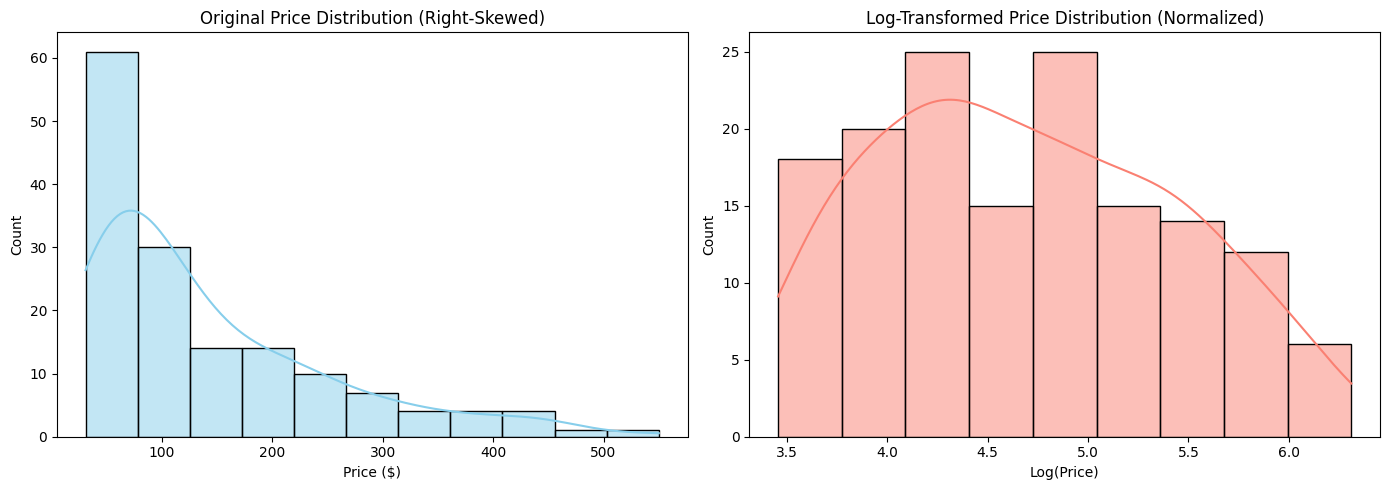

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Apply log transformation to the skewed 'price' column
df['log_price'] = np.log1p(df['price'])

# 2. Set up the plotting area
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 3. Plot Original Price Distribution
sns.histplot(df['price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Original Price Distribution (Right-Skewed)')
axes[0].set_xlabel('Price ($)')
axes[0].set_ylabel('Count')

# 4. Plot Log-Transformed Price Distribution
sns.histplot(df['log_price'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log-Transformed Price Distribution (Normalized)')
axes[1].set_xlabel('Log(Price)')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?  
2. What transformation did you try, and why?  
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. - I examined the price column, and the original chart showed that most listings had lower prices, while a few had very high prices.

2. - I used np.log1p() to create a new log_price column, which reduced the effect of very high prices and made the distribution less skewed.

3. - The log-transformed chart makes prices easier to compare because the most expensive listings do not take over the visual.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [6]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Initialize the scalers
min_max_scaler = MinMaxScaler()
std_scaler = StandardScaler()

# 1. Apply Min-Max scaling to 'minimum_nights' (ranges 0 to 1)
df['minimum_nights_scaled'] = min_max_scaler.fit_transform(df[['minimum_nights']])

# 2. Apply Z-score standardization to 'number_of_reviews' (mean=0, std=1)
df['number_of_reviews_scaled'] = std_scaler.fit_transform(df[['number_of_reviews']])

# Display the original and scaled columns to verify the result
print("Scales successfully applied!")
display(df[['minimum_nights', 'minimum_nights_scaled', 'number_of_reviews', 'number_of_reviews_scaled']].head())

Scales successfully applied!


,minimum_nights,minimum_nights_scaled,number_of_reviews,number_of_reviews_scaled
0,7,0.206897,29,0.968090
1,1,0.000000,24,-0.002588
2,1,0.000000,18,-1.167403
3,2,0.034483,15,-1.749810
4,30,1.000000,18,-1.167403


### Reflection:
1. What two columns did you scale, and which methods did you use?  
2. When might these scaled values be more useful than the originals?  
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. - I scaled minimum_nights using Min-Max scaling, which changes the values to a range from 0 to 1. I scaled number_of_reviews using Z-score standardization, which centers the values around 0.

2. - The scaled values are more useful when comparing these columns or using them in a model. Scaling prevents number_of_reviews from having too much influence just because it has larger numbers.

3. - An Airbnb data scientist could use these scaled columns in a recommendation or search model. This helps the model consider both booking requirements and listing popularity more fairly.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [7]:
# 1. Group 'number_of_reviews' into 3 bins (Low, Medium, High) using quantiles
df['review_volume'] = pd.qcut(df['number_of_reviews'], q=3, labels=['Low', 'Medium', 'High'])

# 2. Display the distribution of our new categorical column
print("Value counts for the new review_volume category:")
print(df['review_volume'].value_counts())

# 3. Display the first few rows showing original and new columns
display(df[['number_of_reviews', 'review_volume']].head(10))

Value counts for the new review_volume category:
review_volume
Medium    55
Low       50
High      45
Name: count, dtype: int64


,number_of_reviews,review_volume
0,29,High
1,24,Medium
2,18,Low
3,15,Low
4,18,Low
5,29,High
6,38,High
7,22,Medium
8,16,Low
9,27,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. - I grouped the number_of_reviews column into three categories: Low, Medium, and High.

2. - Grouping reviews makes the data easier to understand because people can quickly see whether a listing has low, medium, or high review activity.

3. - This could help Airbnb’s marketing/host support teams identify listings with low review activity, who could then offer those hosts tips or promotions to help increase bookings and reviews.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [8]:
# Create the estimated cost required for the minimum allowed stay
df["minimum_stay_cost"] = df["price"] * df["minimum_nights"]

# Flag listings that require a stay of 30 nights or more
df["stay_type"] = np.where(
    df["minimum_nights"] >= 30,
    "Long-term",
    "Short-term"
)

# Check the new columns
display(df[["price", "minimum_nights", "minimum_stay_cost", "stay_type"]].head())

,price,minimum_nights,minimum_stay_cost,stay_type
0,86.31,7,604.17,Short-term
1,391.21,1,391.21,Short-term
2,188.01,1,188.01,Short-term
3,139.55,2,279.10,Short-term
4,50.35,30,1510.50,Long-term


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. - I created minimum_stay_cost and stay_type. Minimum_stay_cost shows the estimated total cost of the minimum required stay, while stay_type identifies whether a listing is meant for a long-term or short-term stay.

2. - Hosts, pricing managers, and Airbnb platform teams could use these columns.

3. - These variables can help people compare listings more easily, as (for example) a guest can see the real minimum cost to book a listing, while Airbnb can identify listings designed for long-term stays.

## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [9]:
# Remove previously created room-type dummy columns if this cell is run again
old_room_type_columns = [
    column for column in df.columns
    if column.startswith("room_type_")
]
df = df.drop(columns=old_room_type_columns, errors="ignore")

# Create a separate 0/1 column for each room type
room_type_encoded = pd.get_dummies(
    df["room_type"],
    prefix="room_type",
    dtype=int
)

# Add the encoded columns to the dataset
df = pd.concat([df, room_type_encoded], axis=1)

# Check the result
display(df[["room_type"] + list(room_type_encoded.columns)].head())

,room_type,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,Entire home/apt,1,0,0
1,Entire home/apt,1,0,0
2,Entire home/apt,1,0,0
3,Private room,0,1,0
4,Private room,0,1,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. - The column for room_type was encoded since the type of listing can have an effect on the price and on booking demand.

2. - I applied one-hot encoding, which involved creating a column containing either 0 or 1 for each room type.

3. - It is useful for comparing different kinds of listings, such as entire homes, private rooms, and shared rooms, and it also makes it easier to carry out comparisons and such.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [10]:
from google.colab import files

output_file = "cleaned_airbnb_data_7.csv"

df.to_csv(output_file, index=False)

print(f"Saved {output_file}")
print("Final rows:", len(df))
print("Final columns:", len(df.columns))

files.download(output_file)

Saved cleaned_airbnb_data_7.csv
Final rows: 150
Final columns: 16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧
1. - The most interesting thing to do was to create the log_price column since it made the price data easier to examine by preventing a small number of very expensive listings from overwhelming the rest of the chart.

2. - The minimum_stay_cost and stay_type columns would be most useful to hosts and analysts as they make it easier to see how much a guest would have to spend at minimum, and also whether or not the listing is better suited to a long-term stay.

3. If I were to design a dashboard, I would include comparisons of prices, reviews, room types, and the minimum stay costs, which would help people to  compare simila listings and identify trends.

4. This is connected with my learning outcome since I applied Python to convert the raw Airbnb data into more useful information for business decisions.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [11]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 405758 bytes to assignment_07_data_transformation.html
